In [1]:
import numpy as np
from numpy.random import default_rng
from scipy.special import expit, logit

NUM_TESTERS = 200
NUM_SMART_TESTERS = 100
NUM_QUESTIONS = 1200
NUM_HARD_QUESTIONS = 800

In [2]:
B_levels = (0, 2, 64, 128, 256, 1024, 4096, 8192)
print(np.log1p(B_levels))
print(np.log1p(B_levels)*0.4-1.5)
print(np.log1p(B_levels)*0.1-1.0)
# print(np.log2(B_levels))

[0.         1.09861229 4.17438727 4.8598124  5.54907608 6.93244789
 8.31801028 9.01103541]
[-1.5        -1.06055508  0.16975491  0.44392496  0.71963043  1.27297916
  1.82720411  2.10441416]
[-1.         -0.89013877 -0.58256127 -0.51401876 -0.44509239 -0.30675521
 -0.16819897 -0.09889646]


In [3]:
def make_3pl_toy(*,
    Q_easy: int = NUM_QUESTIONS - NUM_HARD_QUESTIONS,
    Q_hard: int = NUM_HARD_QUESTIONS,
    N_normal: int = NUM_TESTERS - NUM_SMART_TESTERS,
    N_smart: int = NUM_SMART_TESTERS,
    a_easy: float = 2.0, 
    a_hard: float = 2.0,
    b_easy: float = -1.0, 
    b_hard: float = 1.0,
    c_val: float = 0.001,
    lambda_easy: float  = 0.99,
    lambda_hard: float  = 0.99,
    theta_normal: float = -1.0,
    theta_smart: float = -1.5,
    gamma_normal: float = 0.1,
    gamma_smart: float = 0.4,
    B_levels = (0, 2, 64, 128, 256, 1024, 4096, 8192), # log1p(B) = [0. 1.1 4.17 4.86 5.55 6.93 8.32 9.01]
    seed: int = 0,
):
    """Rank Paradox Toy 3PL data.
    """
    
    rng = default_rng(seed)
    Q = Q_hard+Q_easy
    N = N_smart + N_normal

    # Ground truth parameters
    theta_j_true = np.array([theta_smart] * N_smart + [theta_normal] * N_normal)
    a_i_true = np.array([a_hard] * Q_hard + [a_easy] * Q_easy)
    b_i_true = np.array([b_hard] * Q_hard + [b_easy] * Q_easy)
    c_i_true = np.full(Q, float(c_val))                                    # (Q,)

    lambda_i_true = np.array([lambda_hard] * Q_hard + [lambda_easy] * Q_easy)
    gamma_j_true = np.array([gamma_smart] * N_smart + [gamma_normal] * N_normal)

    # Budgets and features (absolute)
    x_levels = np.log1p(np.asarray(B_levels, dtype=float))                 # (L,)
    L = len(x_levels)
    idx_base = np.tile(np.arange(L, dtype=int), int(np.ceil(Q / L)))[:Q]   # (Q,)

    X_ij = np.empty((Q, N), dtype=float)
    for j in range(N):
        idx = idx_base.copy(); rng.shuffle(idx)
        X_ij[:, j] = x_levels[idx]
    B_ij = np.expm1(X_ij)

    # Linear predictor & probabilities
    eta_ij = (a_i_true[:, None] * (theta_j_true[None, :] - b_i_true[:, None])
              + (a_i_true * lambda_i_true)[:, None] * gamma_j_true[None, :] * X_ij)
             
    eta_ij = np.clip(eta_ij, -40, 40)
    P_ij = c_i_true[:, None] + (1.0 - c_i_true[:, None]) * expit(eta_ij)

    # Draw responses
    Y_ij = rng.binomial(1, P_ij).astype(float)

    # Heuristic θ_j_max (per-respondent max-budget lift)
    X_max_j = X_ij.max(axis=0)                                # (N,)
    theta_j_max = theta_j_true + (np.mean(lambda_i_true) * gamma_j_true) * X_max_j

    return dict(
        Y_ij=Y_ij, B_ij=B_ij, X_ij=X_ij, c_i_true=c_i_true,
        a_i_true=a_i_true, b_i_true=b_i_true,
        lambda_i_true=lambda_i_true, gamma_j_true=gamma_j_true,
        theta_j_true=theta_j_true, theta_j_max=theta_j_max, P_ij=P_ij,
        meta=dict(B_levels=B_levels, seed=seed),
    )

In [4]:
# Example of budget arranging
Q=22
L=7
rng = np.random.default_rng(0)
idx = np.tile(np.arange(L, dtype=int), int(np.ceil(Q / L)))[:Q]
print(idx)
for i in range(10):
    idx_copy = idx.copy()
    rng.shuffle(idx_copy)
    print(idx_copy)

[0 1 2 3 4 5 6 0 1 2 3 4 5 6 0 1 2 3 4 5 6 0]
[3 5 2 4 2 5 6 6 3 4 1 0 4 6 0 0 5 3 0 2 1 1]
[6 4 4 0 5 6 0 2 3 5 2 1 3 4 2 6 0 1 5 1 3 0]
[0 4 0 3 5 1 4 2 0 2 5 4 6 5 6 2 6 3 1 3 1 0]
[4 2 6 5 4 2 1 0 3 0 3 1 6 5 5 2 4 0 6 0 3 1]
[1 1 5 6 0 5 3 3 4 5 0 1 2 6 4 6 0 2 2 3 4 0]
[0 1 2 4 0 0 5 6 4 3 0 4 2 6 6 5 1 3 2 1 5 3]
[1 5 6 1 1 4 3 0 6 4 0 0 2 0 5 3 6 2 4 5 3 2]
[0 6 2 0 3 4 6 6 3 1 5 1 4 0 1 4 2 5 2 3 0 5]
[4 2 4 4 5 0 2 0 1 1 0 6 5 2 3 0 6 3 3 1 6 5]
[0 4 0 3 1 5 1 3 6 2 0 1 6 0 5 3 5 4 6 2 2 4]


In [5]:
toy_data = make_3pl_toy(seed=1)
print(toy_data['Y_ij'].shape)

(1200, 200)


## Various EDA

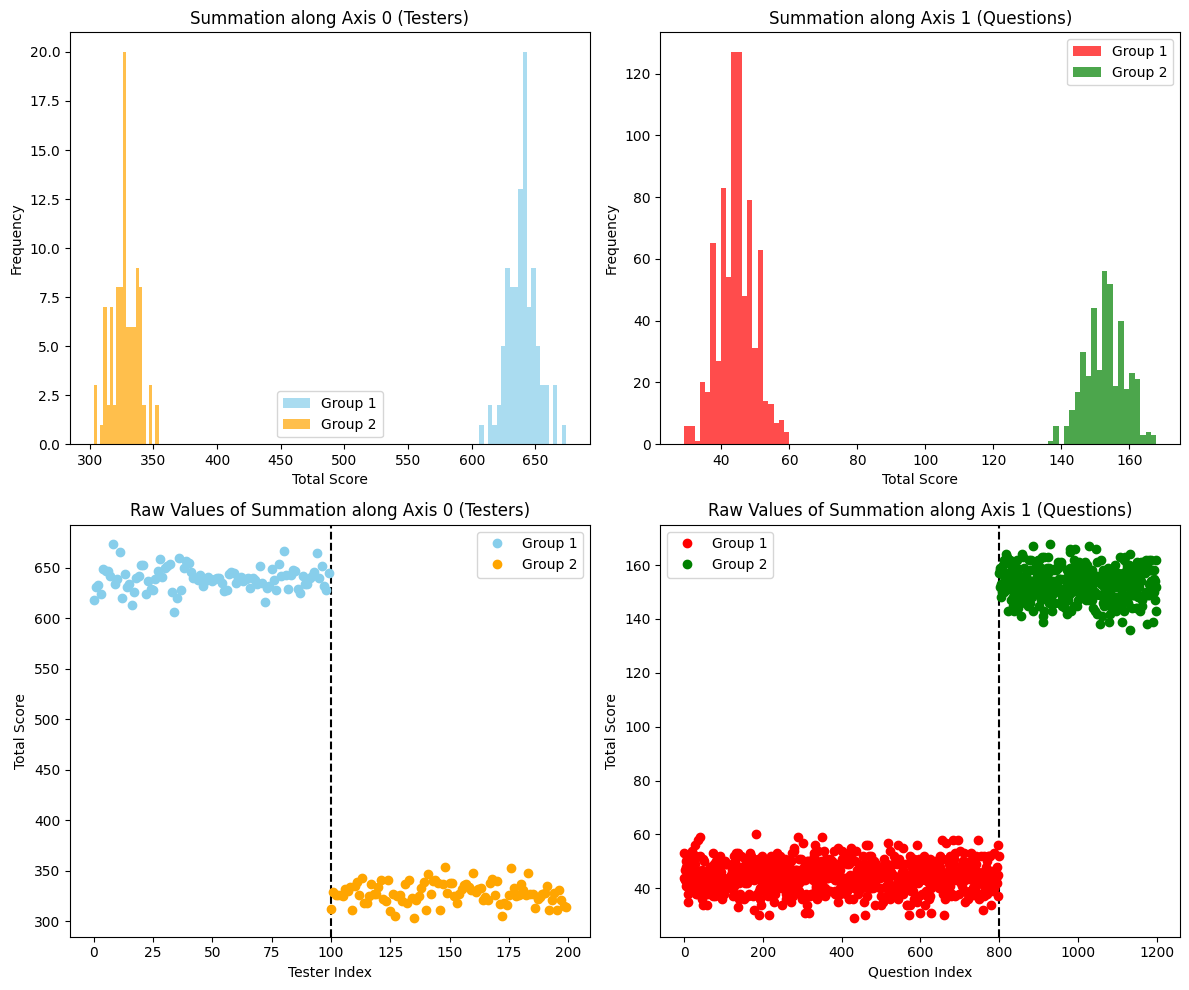

In [6]:
from reasoning_aware_irt.utils import visualize_score_matrix

visualize_score_matrix(toy_data['Y_ij'], tester_threshold_idx=NUM_SMART_TESTERS, question_threshold_idx=NUM_HARD_QUESTIONS)

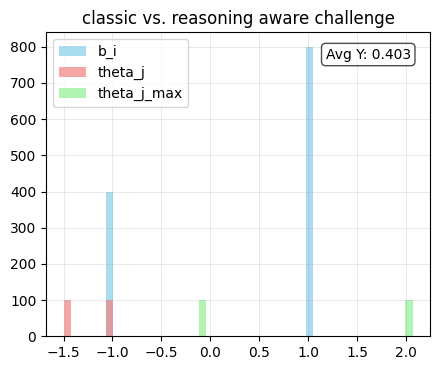

In [7]:
from reasoning_aware_irt.utils import plot_multiple_b_theta_histograms

_, _ = plot_multiple_b_theta_histograms([toy_data], ['classic vs. reasoning aware challenge'], plots_per_row=2, avg_Y_list=[toy_data['Y_ij'].mean()])

In [8]:
from reasoning_aware_irt.precondition_check import DataPreChecker
chk = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data.get('P_ij'))
ok, warn, res = chk.run_all_tests()

[PASS] Variance/Entropy: Items=0.85, Models=1.00
[PASS] Fisher Proxy: Items=0.1744, Models=0.2236
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=190.63, Ratio=0.99
[PASS] Ability-Budget Confounding Corr=-0.0265
[PASS] Budget-Response Association: Signal Prop=1.000 with threshold=0.11
[PASS] Budget-Response with PROB: Signal Prop=1.000 with threshold=0.11


-1.25 0.25


/workspaces/reasoning-aware-irt/reasoning_aware_irt/utils.py:444: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


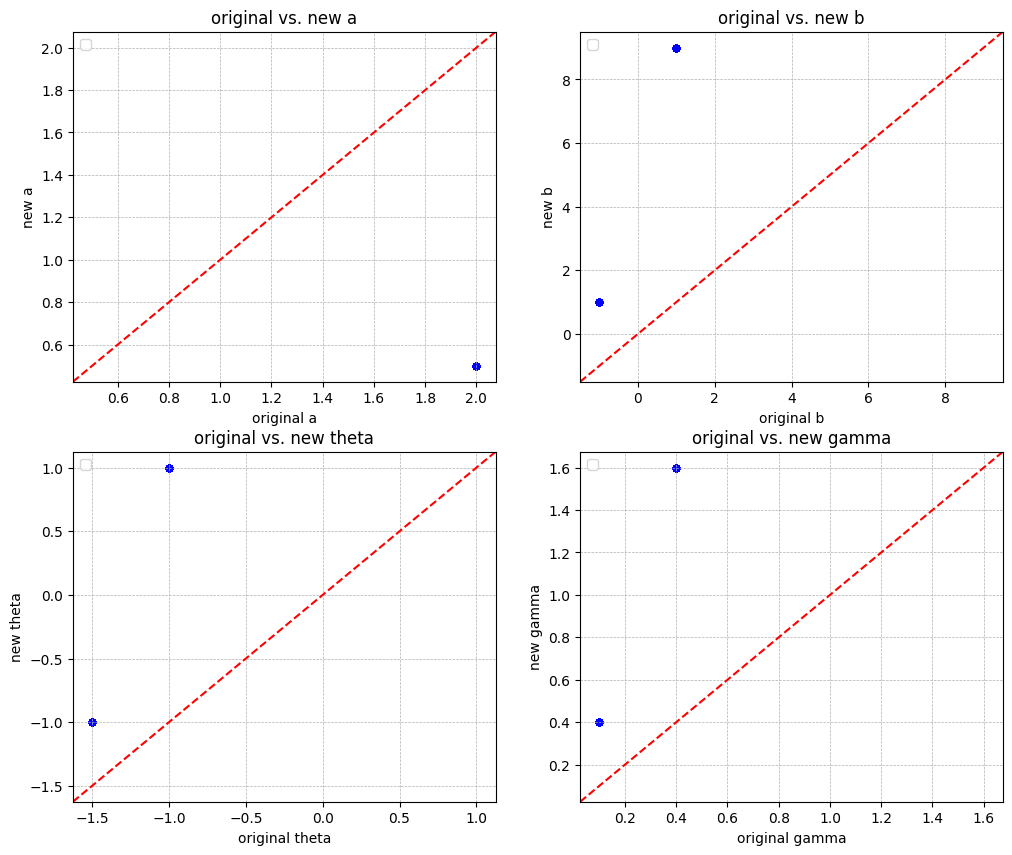

In [9]:
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se, location_scale_transform
import matplotlib.pyplot as plt
new_theta, mu, sigma = location_scale_transform(toy_data["theta_j_true"])
print(mu,sigma)

new_b, _, _ = location_scale_transform(toy_data["b_i_true"], mu, sigma)
new_a = toy_data["a_i_true"]*sigma
new_gamma = toy_data["gamma_j_true"]/sigma

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration
s = "a"
plot_parameter_scatter_with_se(axes[0], toy_data[f"{s}_i_true"], new_a, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "b"
plot_parameter_scatter_with_se(axes[1], toy_data[f"{s}_i_true"], new_b, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "theta"
plot_parameter_scatter_with_se(axes[2], toy_data[f"{s}_j_true"], new_theta, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "gamma"
plot_parameter_scatter_with_se(axes[3], toy_data[f"{s}_j_true"], new_gamma, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")


# Classic EM & Reasoning-Aware GEM

In [10]:
from reasoning_aware_irt.classic_irt_em import IRT3PLCalibrator
from reasoning_aware_irt.classic_irt_em import ClassicCalibrationData, ClassicCalibrationConfig

In [11]:
from reasoning_aware_irt.gem import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem import ReasoningAware3PLCalibrator

## EM

In [18]:
data = ClassicCalibrationData(Y_ij=toy_data["Y_ij"], c_i=toy_data["c_i_true"])
cfg = ClassicCalibrationConfig(
    gh_nodes=30, tol=1e-3,
    max_iter=75, verbose=True,
)

calibrator = IRT3PLCalibrator(cfg)

In [19]:
classic_fit_results = calibrator.fit(data)

iter=  1  LL=-112149.535708  dLL=4.448e+03
iter=  2  LL=-112145.259154  dLL=4.277e+00
iter=  3  LL=-112145.254938  dLL=4.216e-03
iter=  4  LL=-112145.258048  dLL=-3.110e-03
iter=  5  LL=-112145.257301  dLL=7.468e-04
converged at iter 5


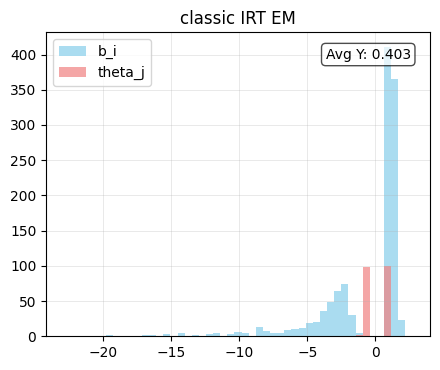

In [20]:
_, _ = plot_multiple_b_theta_histograms([classic_fit_results], ['classic IRT EM'], plots_per_row=2, avg_Y_list=[toy_data['Y_ij'].mean()])

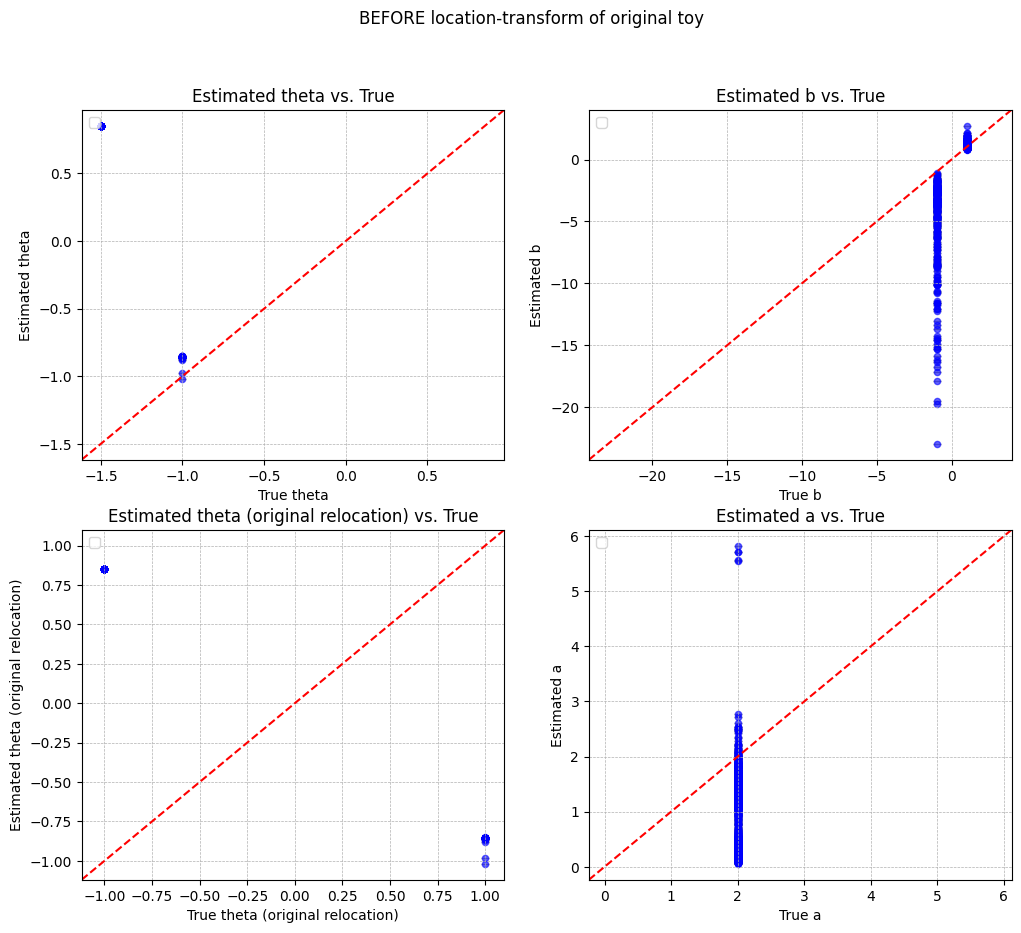

In [21]:
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se
from scipy.special import logit

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration
fig.suptitle('BEFORE location-transform of original toy')

# pre location-transform of original toy
plot_parameter_scatter_with_se(axes[0], toy_data["theta_j_true"], classic_fit_results.theta_j_mean, None, "theta")
plot_parameter_scatter_with_se(axes[1], toy_data["b_i_true"], classic_fit_results.b_i, None, "b")
plot_parameter_scatter_with_se(axes[2], new_theta, classic_fit_results.theta_j_mean, None, "theta (original relocation)")
plot_parameter_scatter_with_se(axes[3], toy_data["a_i_true"], classic_fit_results.a_i, None, "a")


## Reasoning-Aware GEM

In [14]:
data = CalibrationData(Y_ij=toy_data["Y_ij"], B_ij=toy_data["B_ij"], c_i=toy_data["c_i_true"])
cfg = CalibrationConfig(
    gh_nodes=25, max_iter=75, verbose=True, tol=1e-3, ridge_lambda=10.0
)

calibrator = ReasoningAware3PLCalibrator(cfg)

In [15]:
a0, b0, lamb0, gam0 = calibrator._init_params(toy_data['Y_ij'], toy_data['c_i_true'])
print(b0[:20], b0[-20:])

[1.27022219 1.0239214  1.2997077  1.18455472 1.10262031 1.36022212
 1.15685488 1.07604995 1.36022212 1.45528723 1.55632809 1.07604995
 1.18455472 1.36022212 1.32969869 1.24121698 1.36022212 1.24121698
 1.18455472 1.12954952] [-1.44877484 -1.07077749 -1.32365879 -1.32365879 -1.17898228 -1.44877484
 -1.20701166 -1.32365879 -1.20701166 -1.07077749 -0.82216018 -1.15136285
 -1.23547147 -1.09727807 -1.32365879 -1.20701166 -1.0187792  -0.91839378
 -1.15136285 -1.44877484]


In [16]:
fit_results = calibrator.fit(data)

mu_theta = -0.826, sigma_theta =  0.99401
iter   1  ll=-105116.567789   dLL=nan
mu_theta = -0.188, sigma_theta =  0.97082
iter   2  ll=-93173.158764   dLL=nan
mu_theta = -0.175, sigma_theta =  0.94951
iter   3  ll=-91107.696809   dLL=2.065e+03
mu_theta = -0.172, sigma_theta =  0.94608
iter   4  ll=-90071.027102   dLL=1.037e+03
mu_theta = -0.172, sigma_theta =  0.94623
iter   5  ll=-89394.360601   dLL=6.767e+02
mu_theta = -0.172, sigma_theta =  0.94623
iter   6  ll=-88760.154378   dLL=6.342e+02
mu_theta = -0.172, sigma_theta =  0.94622
iter   7  ll=-88111.158439   dLL=6.490e+02
mu_theta = -0.172, sigma_theta =  0.94607
iter   8  ll=-87485.020417   dLL=6.261e+02
mu_theta = -0.167, sigma_theta =  0.94286
iter   9  ll=-86898.219521   dLL=5.868e+02
mu_theta = -0.153, sigma_theta =  0.93531
iter  10  ll=-86294.905813   dLL=6.033e+02
mu_theta = -0.128, sigma_theta =  0.91975
iter  11  ll=-85622.584867   dLL=6.723e+02
mu_theta = -0.115, sigma_theta =  0.91002
iter  12  ll=-84889.228212   dLL=7

In [ ]:
# fit_results.gamma_j
# toy_data["gamma_j_true"]
# new_gamma
# fit_results.b_bracket_half_tau

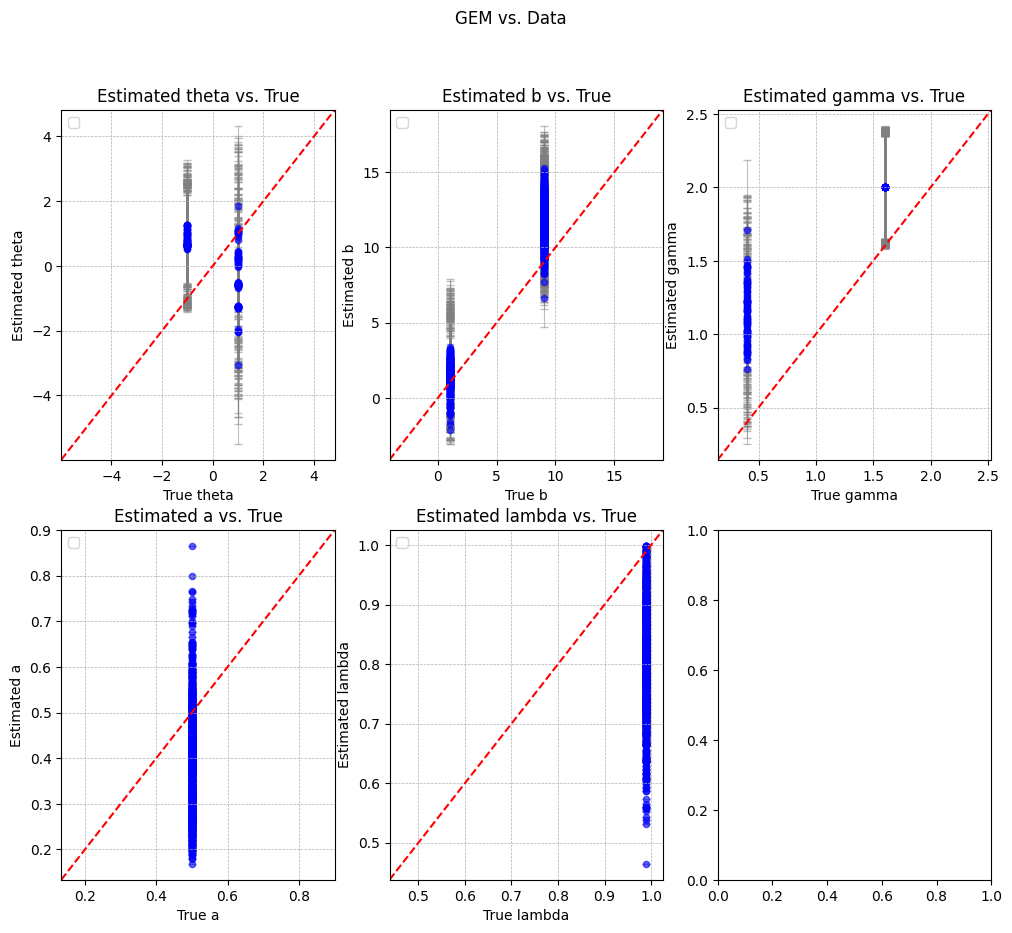

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration
fig.suptitle('GEM vs. Data')

# pre location-transform of original toy
plot_parameter_scatter_with_se(axes[0], new_theta, fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta")
plot_parameter_scatter_with_se(axes[1], new_b, fit_results.b_i, fit_results.b_bracket_half_tau, "b")
plot_parameter_scatter_with_se(axes[2], new_gamma, fit_results.gamma_j, fit_results.gamma_bracket_half_tau, "gamma")
plot_parameter_scatter_with_se(axes[3], new_a, fit_results.a_i, None, "a")
plot_parameter_scatter_with_se(axes[4], toy_data["lambda_i_true"], fit_results.lambda_i, None, "lambda")
# plot_parameter_scatter_with_se(axes[5], new_theta, fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta (original relocation)")